# **Question 13: PCA**

##### **Aim**: Apply PCA to the standardized numerical attributes of the Iris dataset to reduce them to two principal components. Train a classifier using the reduced features and report accuracy, precision, recall and F1-score.

###### **Experiment reference**: Experiment 9

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [7]:
# Step 2: Load the Iris dataset

iris = pd.read_csv('/content/Iris.csv')
df=pd.DataFrame(iris)
print("Shape of dataset : ",df.shape)
print("\n")
display(df.head())

Shape of dataset :  (150, 6)




,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [12]:
# Step 3: Choose four numerical features and target Species

cols=['SepalLengthCm','SepalWidthCm','PetalLengthCm','PetalWidthCm']
X = df[cols]
y = df['Species']
print("Original feature count:", X.shape[1])
print("Number of categories  :", y.nunique())

Original feature count: 4
Number of categories  : 3


In [13]:
# Step 4: Stratified 80/20 split, then standardize without leakage

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print('Train:', X_train.shape, '| Test:', X_test.shape)

Train: (120, 4) | Test: (30, 4)


In [29]:
# Step 5: Fit PCA (2 components) on the training data only

pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)
print("Reduced shape            :", X_train_pca.shape)
print("Explained variance ratios:", pca.explained_variance_ratio_.round(4))
print(f"Total explained variance : {pca.explained_variance_ratio_.sum():.2%}")

Reduced shape            : (120, 2)
Explained variance ratios: [0.7268 0.2307]
Total explained variance : 95.74%


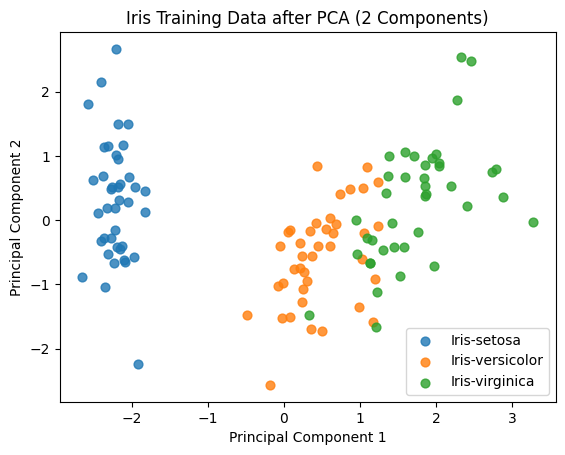

In [34]:
# Step 6: Show the two principal components in a scatter plot

for species in sorted(y.unique()):
    keep = y_train.to_numpy() == species
    plt.scatter(X_train_pca[keep, 0], X_train_pca[keep, 1], label=species, alpha=0.8, s=40)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Iris Training Data after PCA (2 Components)")
plt.legend()
plt.show()

In [37]:
# Step 7: Train a classifier using ONLY the two PCA components

model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_pca, y_train)
y_pred = model.predict(X_test_pca)
print("First ten predicted species:")
print(y_pred[:10])

First ten predicted species:
['Iris-setosa' 'Iris-versicolor' 'Iris-versicolor' 'Iris-versicolor'
 'Iris-setosa' 'Iris-versicolor' 'Iris-setosa' 'Iris-setosa'
 'Iris-virginica' 'Iris-versicolor']


In [39]:
# Step 8: Evaluate the PCA-based classifier (macro metrics across 3 classes)

print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, average="macro", zero_division=0):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred, average="macro", zero_division=0):.4f}")
print(f"F1-score : {f1_score(y_test, y_pred, average="macro", zero_division=0):.4f}")
print("Observation: PCA reduces four inputs to two; classification is evaluated on untouched test data.")

Accuracy : 0.9000
Precision: 0.9024
Recall   : 0.9000
F1-score : 0.8997
Observation: PCA reduces four inputs to two; classification is evaluated on untouched test data.
